# Effect of Different n Values on Stability and Eigenvalues

See how different Hill coefficients (n values) for each neuron type (r, g, b, y) affect network stability

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle


# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal


## Modified Functions with Different n Values

We modify the Naka-Rushton function and circuit functions to accept different n values for each neuron type: n_r, n_g, n_b, n_y.


In [2]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r=4, n_b=4, n_g=4):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r=4, n_b=4, n_g=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y


## Dynamics Function and Stability Analysis

We define the dynamics function F(s) and compute stability with different n values.


In [3]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=4, n_b=4, n_g=4, n_y=4):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [4]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")


Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [6]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


## Different n Value Combinations

We'll test different combinations of n values for each neuron type and analyze their effects on stability and eigenvalues.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


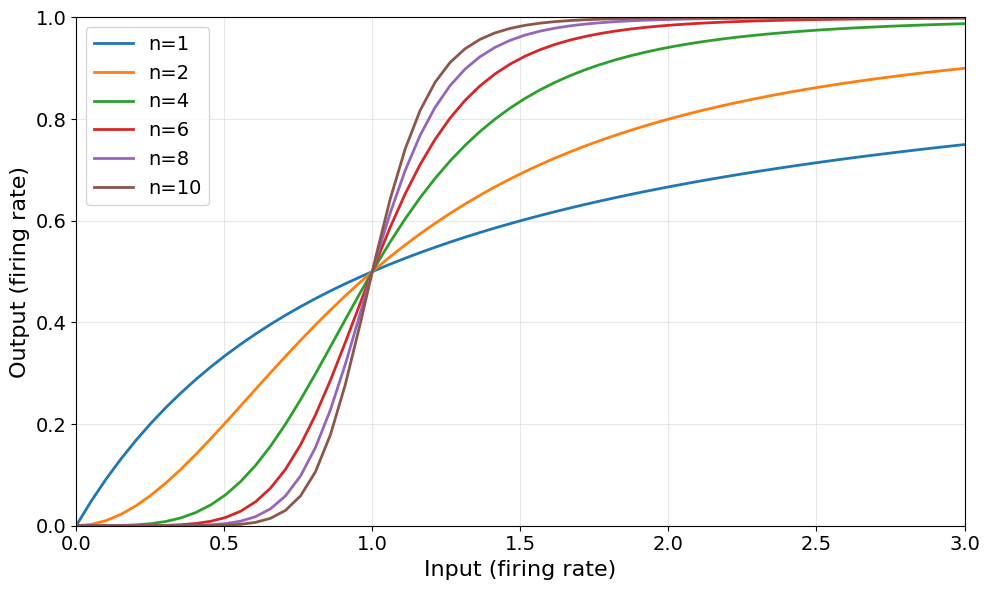

In [7]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [1, 2, 4, 6, 8, 10]

plt.figure(figsize=(10, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=16)
plt.ylabel('Output (firing rate)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
#plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Target firing rate (0.5)')
plt.tick_params(axis='both', direction='out', labelsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig(f'Figures/Naka_Rushton.eps')
plt.show()

In [8]:
# Define n values to test

# Test different combinations - all values must come from n_values_to_test
n_combinations = [
    # Baseline: all same (lowest value)
    {'n_r': 4, 'n_b': 4, 'n_g': 4, 'n_y': 4, 'name': 'Baseline (all n=4)'},

    {'n_r': 1.98, 'n_b': 1.11, 'n_g': 2.06, 'n_y': 3, 'name': 'r=1.98, b=1.11, g=2.06, y=3'},
]

print(f"Testing {len(n_combinations)} different n value combinations")
for i, combo in enumerate(n_combinations):
    print(f"{i+1}. {combo['name']}: n_r={combo['n_r']}, n_b={combo['n_b']}, n_g={combo['n_g']}, n_y={combo['n_y']}")


Testing 2 different n value combinations
1. Baseline (all n=4): n_r=4, n_b=4, n_g=4, n_y=4
2. r=1.98, b=1.11, g=2.06, y=3: n_r=1.98, n_b=1.11, n_g=2.06, n_y=3


## Stability Analysis for Different n Values

For each combination of n values, we compute:
1. Stability (whether all eigenvalues have negative real parts)
2. Real parts of eigenvalues



In [16]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 20 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 20 samples for analysis


In [17]:
# Analyze stability for each n combination

stability_results_all = {}

for combo in n_combinations:
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']

    print(f"Analyzing: {name}")


    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []

    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]

        # Get fixed point outputs with new n values
        try:
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])

            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)

            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

            # Compute stability
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            stability_results.append(result)

            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])

        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue

    # Store results
    stability_results_all[name] = {
        'results': stability_results,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'all_eigenvalues': all_eigenvalues,
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y,
        'stable_count': sum(1 for r in stability_results if r['is_stable']),
        'total_count': len(stability_results)
    }

    stable_pct = 100 * stability_results_all[name]['stable_count'] / stability_results_all[name]['total_count']
    print(stable_pct)

Analyzing: Baseline (all n=4)
100.0
Analyzing: r=1.98, b=1.11, g=2.06, y=3
80.0


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


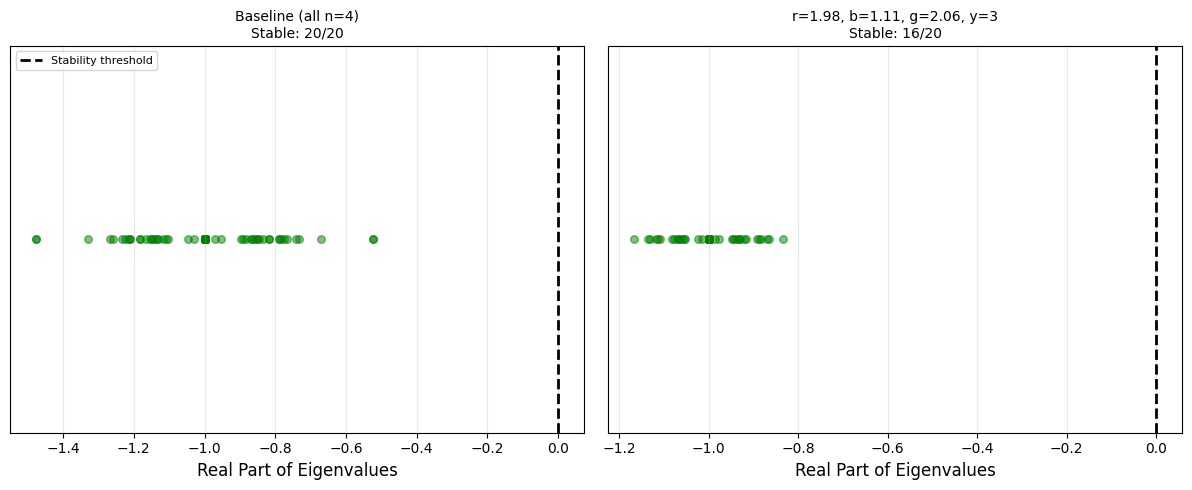

In [18]:
# Plot stability results
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]

    # Plot eigenvalues for all samples - only real parts
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']

        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        # Plot real parts as points along x-axis (y=0 for all)
        ax.scatter(real_parts, np.zeros_like(real_parts), alpha=0.5, s=30, color=color)

    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part of Eigenvalues', fontsize=12)
    ax.set_ylabel('', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3, axis='x')
    ax.set_ylim(-0.1, 0.1)  # Small range around y=0
    ax.set_yticks([])  # Remove y-axis ticks
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


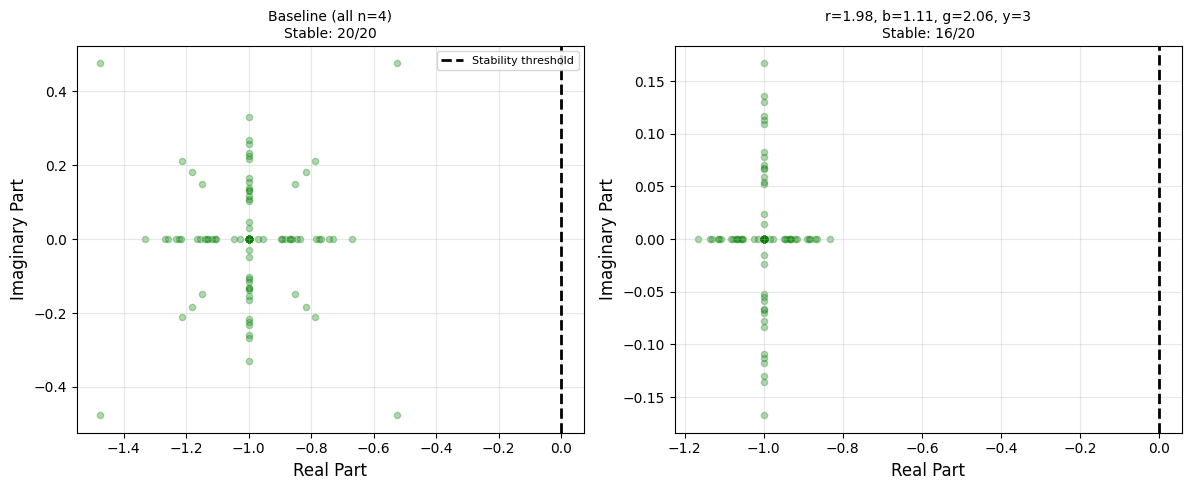

In [19]:
# Plot stability results (complex plane - real vs imaginary parts)
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]

    # Plot eigenvalues for all samples
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        imag_parts = result['imag_parts']

        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        ax.scatter(real_parts, imag_parts, alpha=0.3, s=20, color=color)

    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part', fontsize=12)
    ax.set_ylabel('Imaginary Part', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()

In [20]:
# Diagnostic: per-sample max real part and stability (explains 4/5 vs "all negative")
for name, data in stability_results_all.items():
    print(f"\n{name}:")
    for i, r in enumerate(data['results']):
        max_real = np.max(r['real_parts'])
        stable = r['is_stable']
        print(f"  Sample {i+1}: max(real) = {max_real:.6e}, stable = {stable}")


Baseline (all n=4):
  Sample 1: max(real) = -7.418442e-01, stable = True
  Sample 2: max(real) = -8.171684e-01, stable = True
  Sample 3: max(real) = -8.967671e-01, stable = True
  Sample 4: max(real) = -8.611916e-01, stable = True
  Sample 5: max(real) = -7.313627e-01, stable = True
  Sample 6: max(real) = -8.832471e-01, stable = True
  Sample 7: max(real) = -6.691746e-01, stable = True
  Sample 8: max(real) = -8.513991e-01, stable = True
  Sample 9: max(real) = -8.665235e-01, stable = True
  Sample 10: max(real) = -8.920479e-01, stable = True
  Sample 11: max(real) = -8.456026e-01, stable = True
  Sample 12: max(real) = -7.757967e-01, stable = True
  Sample 13: max(real) = -9.709490e-01, stable = True
  Sample 14: max(real) = -8.690199e-01, stable = True
  Sample 15: max(real) = -8.355720e-01, stable = True
  Sample 16: max(real) = -7.679725e-01, stable = True
  Sample 17: max(real) = -9.525855e-01, stable = True
  Sample 18: max(real) = -7.880456e-01, stable = True
  Sample 19: max

In [ ]:
# Find where NaN comes from (fixed point vs Jacobian) for any sample with NaN eigenvalues
for name, data in stability_results_all.items():
    n_r, n_b, n_g, n_y = data['n_r'], data['n_b'], data['n_g'], data['n_y']
    for i, r in enumerate(data['results']):
        if np.any(np.isnan(r['real_parts'])):
            theta_star = theta_subset[i]
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)
            s_star = jnp.concatenate([r_star, g_star, y_star])
            s_star_np = np.array(s_star)
            has_nan_s = np.any(np.isnan(s_star_np))
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            J_np = np.array(result['J'])
            has_nan_J = np.any(np.isnan(J_np))
            print(f"{name} — Sample {i+1}:")
            print(f"  s_star has NaN: {has_nan_s}  (fixed point failed or produced NaN)")
            print(f"  J has NaN:     {has_nan_J}  (Jacobian at s_star has NaN, e.g. negative input to x**n with non-integer n)")
            print(f"  s_star = {s_star_np}")
            if has_nan_s:
                print("  → Likely cause: fixed point solver did not converge for this (theta, n) combination.")
            elif has_nan_J:
                print("  → Likely cause: negative input to Naka-Rushton (or its derivative) with non-integer n.")

Try just a few to see how star shape forms


In [28]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 3
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 3 samples for analysis


In [ ]:
# Analyze stability for each n combination

stability_results_all = {}

for combo in n_combinations:
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']

    print(f"\n{'='*70}")
    print(f"Analyzing: {name}")
    print(f"{'='*70}")

    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []

    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]

        # Get fixed point outputs with new n values
        try:
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])

            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)

            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

            # Compute stability
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            stability_results.append(result)

            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])

        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue

    # Store results
    stability_results_all[name] = {
        'results': stability_results,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'all_eigenvalues': all_eigenvalues,
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y,
        'stable_count': sum(1 for r in stability_results if r['is_stable']),
        'total_count': len(stability_results)
    }

    stable_pct = 100 * stability_results_all[name]['stable_count'] / stability_results_all[name]['total_count']
    print(f"\nStability: {stability_results_all[name]['stable_count']}/{stability_results_all[name]['total_count']} stable ({stable_pct:.1f}%)")
    print(f"Max real part range: [{np.min(max_real_parts):.4f}, {np.max(max_real_parts):.4f}]")
    print(f"Min real part range: [{np.min(min_real_parts):.4f}, {np.max(min_real_parts):.4f}]")



Analyzing: Baseline (all n=4)

Stability: 3/3 stable (100.0%)
Max real part range: [-0.8968, -0.7418]
Min real part range: [-1.2582, -1.1032]

Analyzing: r=8, b=2.85, g=4.8, y=5.5

Stability: 2/3 stable (66.7%)
Max real part range: [nan, nan]
Min real part range: [nan, nan]

Analyzing: r=11, b=4, g=6, y=7

Stability: 3/3 stable (100.0%)
Max real part range: [-0.9778, -0.4757]
Min real part range: [-1.5243, -1.0222]


[-1.        -1.        -1.258157  -0.9999995 -0.9999995 -0.7418442]
[-1.        -1.        -1.1828315 -1.1828315 -0.8171684 -0.8171684]
[-1.         -1.         -1.1032343  -0.9999995  -0.9999995  -0.89676714]
[-1.         -1.         -1.3999355  -1.         -1.         -0.60006547]
[nan nan nan nan nan nan]
[-1.        -1.        -1.1599277 -1.0000007 -1.0000007 -0.8400721]
[-1.         -1.         -1.5243186  -0.99999976 -0.99999976 -0.4756811 ]
[-1.         -1.         -1.0221802  -1.0221802  -0.97781897 -0.97781897]
[-1.        -1.        -1.209668  -1.0000005 -1.0000005 -0.7903324]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


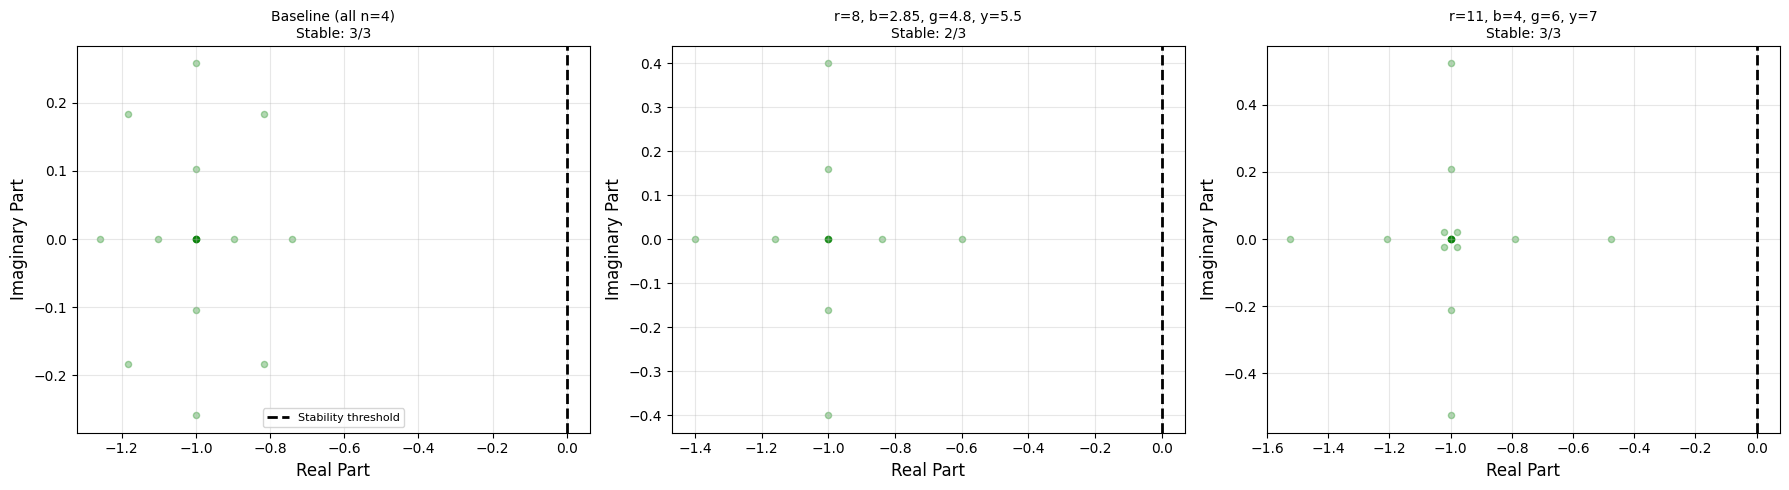

In [ ]:
# Plot stability results (complex plane - real vs imaginary parts)
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]

    # Plot eigenvalues for all samples
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        imag_parts = result['imag_parts']
        print(real_parts)

        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        ax.scatter(real_parts, imag_parts, alpha=0.3, s=20, color=color)

    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part', fontsize=12)
    ax.set_ylabel('Imaginary Part', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()